# Ambiguity-Ladder Debugging

**Problem.** Stage A was meant to show the score d = log P(higher class) − log P(lower class) rising smoothly from level 1 to level 5. The middle levels (2–4) should land in the ambiguous zone, with probability between 0.2 and 0.8. This notebook checks whether the v1 ladders do that and, if not, finds out why and builds candidate v2 ladders.

**Structure**
1. **Part 1, diagnose the Stage A run (offline).** Load `runs/<model>/stage_A/scores.jsonl`, apply the PLAN.md gate, and separate d into level, wording, prompt order and base effects.
2. **Part 2, live probes (GPU).** Score variants of the frame and a factorial pool of candidate evidence sentences, on **tuning bases only**.
3. **Part 3, build and validate a ladder.** Choose middle levels from the pool by target probability, then check the result on the **held-out bases** with the same gate, and on the second model.

**Protocol guardrails (PLAN.md § Procedure).** Only no-country text is scored here. Probe outputs go to `/fs/clip-scratch/pramu/ladder_debug/`, never to `interpretability/runs/`. Nothing here edits `ladders.json`. Part 3 prints a proposed v2 phrase list for you to review. Any adopted version still needs a new snapshot and a formal Stage A run.

## Setup
Paths, constants and the v1 ladder definitions. `HF_HOME` is set before anything imports `huggingface_hub`.

In [1]:
import hashlib
import json
import math
import os
import sys
import time
from itertools import combinations
from pathlib import Path

os.environ.setdefault("HF_HOME", "/fs/clip-scratch/rlab_models")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

REPO = Path("/fs/nexus-projects/rlab/pramu/geovariance_of_llm_decisions")
sys.path.insert(0, str(REPO))
DATA = REPO / "interpretability" / "data"
SNAP = DATA / "stimuli"
RUNS = REPO / "interpretability" / "runs"
SCRATCH = Path("/fs/clip-scratch/pramu/ladder_debug")
SCRATCH.mkdir(parents=True, exist_ok=True)

BOUNDARIES = ("PR", "BV")
VERSIONS = ("defined", "undefined")
LADDERS = json.loads((DATA / "ladders.json").read_text())
HIGHER = {b: LADDERS["boundaries"][b]["higher_class"] for b in BOUNDARIES}
LOWER = {b: LADDERS["boundaries"][b]["lower_class"] for b in BOUNDARIES}
V1_FRAME = {b: LADDERS["boundaries"][b]["frame"] for b in BOUNDARIES}
V1_PHRASES = {
    b: {lv["level"]: lv["wordings"] for lv in LADDERS["boundaries"][b]["levels"]}
    for b in BOUNDARIES
}
BASES = {b: pd.read_csv(DATA / f"bases_{b.lower()}.csv") for b in BOUNDARIES}
SYSTEM_PROMPTS = pd.read_csv(SNAP / "system_prompts.csv").set_index("task_id")

# The gate's ambiguity window, in d units: p in [0.2, 0.8]  <=>  |d| <= logit(0.8)
P_LO, P_HI = 0.2, 0.8
D_WINDOW = math.log(P_HI / (1 - P_HI))

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Part 1: Diagnose the Stage A Run

## Load the Run
Each record is one prompt (stimulus × task version × order). The cell computes d for each prompt, then averages the two orders, d = (d_A + d_B)/2, as PLAN.md § Analysis specifies. `p_hi` = sigmoid(d) is the renormalized probability of the higher-evidence class.

In [2]:
MODEL_KEY_RUN = "llama3.2-3b"  # the model whose Stage A run is diagnosed in Part 1


def load_run(model_key, stage="A"):
    recs = []
    with open(RUNS / model_key / f"stage_{stage}" / "scores.jsonl") as fh:
        for line in fh:
            r = json.loads(line)
            boundary, base, lvl, wd, country = r["stimulus_id"].split(":")
            _, version, order = r["task_id"].split(":")
            a = r["answers"]
            recs.append(
                dict(
                    pass_=r["pass"],
                    prompt_id=r["prompt_id"],
                    boundary=boundary,
                    base_id=base,
                    level=int(lvl[1:]),
                    wording=int(wd[1:]),
                    version=version,
                    order=order,
                    lp_hi=a[HIGHER[boundary]]["logprob"],
                    lp_lo=a[LOWER[boundary]]["logprob"],
                    mass=r["answer_mass"],
                )
            )
    df = pd.DataFrame(recs)
    df["d"] = df.lp_hi - df.lp_lo
    return df


def by_stimulus(prompts, keys=("boundary", "base_id", "level", "wording", "version")):
    # Average the two prompt orders into one score per stimulus x task version.
    wide = prompts.pivot_table(index=list(keys), columns="order", values="d").reset_index()
    wide["d"] = (wide["A"] + wide["B"]) / 2
    wide["order_effect"] = wide["A"] - wide["B"]
    wide["p_hi"] = sigmoid(wide["d"])
    return wide


run_all = load_run(MODEL_KEY_RUN)
run = run_all[run_all.pass_ == "main"].copy()
stim = by_stimulus(run)
print(f"{len(run)} main prompts, {len(stim)} stimulus x version scores")
stim.head()

1920 main prompts, 960 stimulus x version scores


order,boundary,base_id,level,wording,version,A,B,d,order_effect,p_hi
0,BV,bv_01,1,1,defined,-13.37,-17.44,-15.41,4.06,2.04e-07
1,BV,bv_01,1,1,undefined,-4.75,-18.06,-11.41,13.31,1.11e-05
2,BV,bv_01,1,2,defined,-15.75,-18.06,-16.91,2.31,4.55e-08
3,BV,bv_01,1,2,undefined,-9.50,-18.69,-14.09,9.19,7.57e-07
4,BV,bv_01,2,1,defined,-6.50,-7.50,-7.00,1.00,9.11e-04


## Apply the Stage A Gate
The PLAN.md criteria, for each boundary × task version:
- anchor accuracy ≥ 90% at level 1 and at level 5;
- Spearman ρ > 0 in ≥ 80% of base × wording ladders;
- ≥ 50% of bases with some middle level at 0.2 ≤ p ≤ 0.8;
- median answer mass ≥ 0.9.

Part 3 reuses `gate()` on the proposed ladders.

In [3]:
def gate(stim, prompts=None):
    rows = []
    for (b, v), g in stim.groupby(["boundary", "version"]):
        rho = g.groupby(["base_id", "wording"]).apply(
            lambda x: spearmanr(x.level, x.d).statistic, include_groups=False
        )
        mid = g[g.level.between(2, 4)]
        ambiguous = mid.groupby("base_id").p_hi.apply(lambda s: s.between(P_LO, P_HI).any())
        row = dict(
            boundary=b,
            version=v,
            anchor_L1=(g[g.level == 1].d < 0).mean(),
            anchor_L5=(g[g.level == 5].d > 0).mean(),
            rho_pos=(rho > 0).mean(),
            ambig_bases=ambiguous.mean(),
        )
        if prompts is not None:
            row["mass_median"] = prompts[(prompts.boundary == b) & (prompts.version == v)].mass.median()
        row["PASS"] = (
            row["anchor_L1"] >= 0.9
            and row["anchor_L5"] >= 0.9
            and row["rho_pos"] >= 0.8
            and row["ambig_bases"] >= 0.5
            and row.get("mass_median", 1.0) >= 0.9
        )
        rows.append(row)
    return pd.DataFrame(rows)


def repeat_check(run_all):
    main = run_all[run_all.pass_ == "main"].set_index("prompt_id")
    rep = run_all[run_all.pass_ == "repeat"].set_index("prompt_id")
    diff = (rep[["lp_hi", "lp_lo"]] - main.loc[rep.index, ["lp_hi", "lp_lo"]]).abs()
    return float(diff.values.max())


print(f"Determinism: max |delta logprob| over repeats = {repeat_check(run_all):.4f} (limit 0.01)")
gate(stim, run)

Determinism: max |delta logprob| over repeats = 0.0000 (limit 0.01)


,boundary,version,anchor_L1,anchor_L5,rho_pos,ambig_bases,mass_median,PASS
0,BV,defined,1.0,0.94,1.0,0.00,1.0,False
1,BV,undefined,1.0,0.50,1.0,0.00,1.0,False
2,PR,defined,1.0,1.00,1.0,0.25,1.0,False
3,PR,undefined,1.0,0.46,1.0,0.00,1.0,False


## Ladder Curves
Each panel is one boundary × task version. Thin lines show the four wording × order cells, averaged over bases. The thick black line is the order-averaged d, with its range across bases shaded. The grey band is the ambiguity window, 0.2 ≤ p ≤ 0.8.

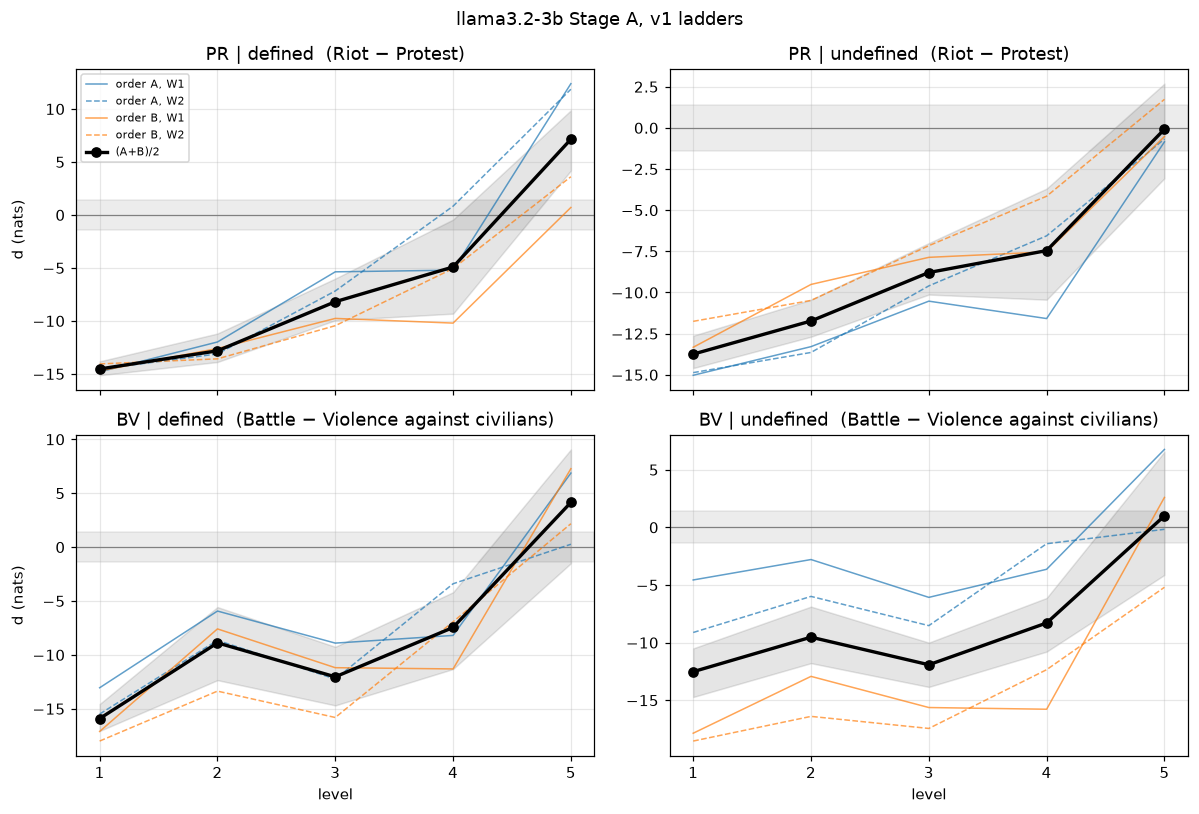

In [4]:
def plot_ladders(prompts, stim, title):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
    styles = {("A", 1): "-", ("A", 2): "--", ("B", 1): "-", ("B", 2): "--"}
    colors = {"A": "tab:blue", "B": "tab:orange"}
    for i, b in enumerate(BOUNDARIES):
        for j, v in enumerate(VERSIONS):
            ax = axes[i, j]
            ax.axhspan(-D_WINDOW, D_WINDOW, color="grey", alpha=0.15)
            ax.axhline(0, color="grey", lw=0.8)
            p = prompts[(prompts.boundary == b) & (prompts.version == v)]
            for (o, w), g in p.groupby(["order", "wording"]):
                m = g.groupby("level").d.mean()
                ax.plot(m.index, m.values, styles[(o, w)], color=colors[o], alpha=0.7, lw=1, label=f"order {o}, W{w}")
            s = stim[(stim.boundary == b) & (stim.version == v)]
            agg = s.groupby("level").d.agg(["mean", "min", "max"])
            ax.fill_between(agg.index, agg["min"], agg["max"], color="k", alpha=0.1)
            ax.plot(agg.index, agg["mean"], "k-o", lw=2.2, label="(A+B)/2")
            ax.set_title(f"{b} | {v}  ({HIGHER[b]} − {LOWER[b]})")
            ax.set_xticks(sorted(s.level.unique()))
            if j == 0:
                ax.set_ylabel("d (nats)")
            if i == 1:
                ax.set_xlabel("level")
    axes[0, 0].legend(fontsize=7, loc="upper left")
    fig.suptitle(title)
    fig.tight_layout()
    return fig


plot_ladders(run, stim, f"{MODEL_KEY_RUN} Stage A, v1 ladders");

## Decompose d by Level, Wording and Order
For each boundary × version × level, the table shows:
- `d`: the order-averaged mean;
- `step`: the change from the previous level;
- `wording_gap`: the mean of W2 − W1, the phrasing effect PLAN.md uses as a reference scale;
- `order_eff`: the mean of d_A − d_B, the position bias;
- `base_sd`: the spread across bases.

A usable ladder needs steps that are large relative to the wording gaps and the base spread.

In [5]:
def decompose(stim):
    w = stim.pivot_table(index=["boundary", "version", "level", "base_id"], columns="wording", values="d")
    gap = (w[2] - w[1]).groupby(["boundary", "version", "level"]).mean().rename("wording_gap")
    t = stim.groupby(["boundary", "version", "level"]).agg(
        d=("d", "mean"), p_hi=("p_hi", "mean"), order_eff=("order_effect", "mean"), base_sd=("d", "std")
    )
    t = t.join(gap)
    t["step"] = t.groupby(["boundary", "version"]).d.diff()
    return t[["d", "p_hi", "step", "wording_gap", "order_eff", "base_sd"]]


decomp = decompose(stim)
decomp

d      p_hi   step  wording_gap  order_eff  base_sd
boundary version   level                                                         
BV       defined   1     -15.91  1.74e-07    NaN        -1.67       3.28     0.87
                   2      -8.88  8.30e-04   7.03        -4.25       3.18     2.29
                   3     -12.04  2.49e-05  -3.15        -3.98       2.92     2.06
                   4      -7.46  3.43e-03   4.58         4.58       3.32     2.46
                   5       4.15  8.68e-01  11.60        -5.85      -1.16     3.18
         undefined 1     -12.52  7.96e-06    NaN        -2.62      11.36     1.40
                   2      -9.53  2.24e-04   2.99        -3.33      10.27     1.74
                   3     -11.92  1.25e-05  -2.39        -2.13       9.24     1.21
                   4      -8.29  6.24e-04   3.62         2.82      11.54     1.53
                   5       1.00  5.30e-01   9.29        -7.36       4.60     3.82
PR       defined   1     -14.53  5.09e-07    NaN         0.46      -0.30     0.29
                   2     -12.82  3.38e-06   1.71        -1.05       0.54     0.64
                   3      -8.19  4.31e-04   4.63        -1.25       3.84     0.93
                   4      -4.91  6.94e-02   3.28         5.59       5.44     2.94
                   5       7.14  9.98e-01  12.05         1.19       9.97     1.46
         undefined 1     -13.74  1.22e-06    NaN         0.87      -2.41     0.50
                   2     -11.73  9.40e-06   2.01        -0.66      -3.47     0.54
                   3      -8.79  2.03e-04   2.94         0.82      -2.55     0.74
                   4      -7.46  3.26e-03   1.33         4.20      -3.23     2.23
                   5      -0.08  4.85e-01   7.38         1.22      -1.37     1.29

## Scale Summary
Each boundary × version is reduced to a few numbers:
- `span`: d(L5) − d(L1);
- `mid_mean`: the mean d over levels 2–4. Ambiguity needs a value near 0;
- `mid_to_L1`: where the middle levels sit between the anchors, from 0 at the L1 anchor to 1 at the L5 anchor;
- `|wording|`: the median absolute wording gap;
- `|order|`: the median absolute order effect;
- `inversions`: the share of base × wording × adjacent-level pairs where d falls as level rises.

In [6]:
def scale_summary(stim):
    rows = []
    for (b, v), g in stim.groupby(["boundary", "version"]):
        lv = g.groupby("level").d.mean()
        w = g.pivot_table(index=["base_id", "level"], columns="wording", values="d")
        seq = g.sort_values("level").groupby(["base_id", "wording"]).d.apply(lambda s: np.diff(s.values))
        inv = np.concatenate(seq.values)
        rows.append(
            dict(
                boundary=b,
                version=v,
                d_L1=lv[1],
                d_L5=lv[5],
                span=lv[5] - lv[1],
                mid_mean=lv[[2, 3, 4]].mean(),
                mid_to_L1=(lv[[2, 3, 4]].mean() - lv[1]) / (lv[5] - lv[1]),
                wording_abs=(w[2] - w[1]).abs().median(),
                order_abs=g.order_effect.abs().median(),
                inversions=(inv < 0).mean(),
            )
        )
    return pd.DataFrame(rows).rename(columns={"wording_abs": "|wording|", "order_abs": "|order|"})


scale_summary(stim)

,boundary,version,d_L1,d_L5,span,mid_mean,mid_to_L1,|wording|,|order|,inversions
0,BV,defined,-15.91,4.15,20.06,-9.46,0.32,4.23,2.88,0.29
1,BV,undefined,-12.52,1.00,13.52,-9.91,0.19,2.84,10.00,0.25
2,PR,defined,-14.53,7.14,21.68,-8.64,0.27,1.19,3.75,0.08
3,PR,undefined,-13.74,-0.08,13.66,-9.32,0.32,0.88,2.78,0.11


## Read-Out from the v1 Run (Llama 3.2, bf16)
Written after running the cells above. Re-check it against the tables if the run changes.

1. **The middle is not ambiguous. It sits close to the lower anchor.** Levels 2–4 give p(Riot) and p(Battle) ≈ 0 in nearly every cell. The model reads "scuffles", "a damaged car, actor unknown" and "unconfirmed stone-throwing" all as clear *Protest*. It reads "disputed identity", "unknown whether armed" and "unconfirmed rifles" all as clear *Violence against civilians*. There is a gradation in d, roughly −15 → −5, but it lies far below the window: the steps are real in log space but never reach the decision boundary.
2. **Some anchors are weak.** PR *undefined* L5 ("threw stones and set a parked car on fire") is **not** called a Riot (p ≈ 0.35–0.75). BV L5 W2 ("belonged to a rival armed group and fired back") is near 0.5. In the PR frame, the word *protest* and the calm closing sentence probably pull towards the lower class, and in the BV frame "opened fire on a group of people… Two people were killed" probably does too. Experiment 1 tests this.
3. **Wording effects match or exceed the level steps.** BV L4 W1 and W2 differ by about 5 nats, and BV L5 W1 and W2 by about 6. BV L3 falls *below* L2 (inversions), so "identity disputed" counts as more Battle-like than "unknown whether armed". The levels are not ordered the way the model reads them.
4. **Order bias is large and depends on the version.** In BV undefined, d_A − d_B ≈ +10 nats: listing Battle first adds about 10 nats to Battle. Averaging the orders removes the bias from d's mean, but a bias this large means the content signal is small by comparison.

**What this means for construction.** The ladder must be placed *empirically*: choose middle-level phrases by where the model actually scores them, not by an a-priori ordering of evidence. The frame should also stop pushing towards the lower class. Parts 2 and 3 do this.

# Part 2: Live Probes

## Load a Model for Probing
This uses the real scorer (`src.interp_score.load_model` / `score_prompt`), so probe scores are directly comparable with Stage A. It pins the revision from the Stage A `run.json`. `DTYPE_OVERRIDE` exists only for exploratory checks: Qwen3-4B needs fp32 (more than 16 GB) for formal scores, but bf16 fits on the A4000 and is close enough for placing a ladder (see Part 3).

In [7]:
import torch

from src import interp_score as S

DEVICE = "cuda"
_loaded = {}


def load_probe_model(model_key, dtype_override=None):
    for key in list(_loaded):  # keep one model in memory at a time
        if key != (model_key, dtype_override):
            del _loaded[key]
            torch.cuda.empty_cache()
    if (model_key, dtype_override) not in _loaded:
        spec = dict(S.MODELS[model_key])
        if dtype_override:
            spec["dtype"] = dtype_override
        run_json = RUNS / model_key / "stage_A" / "run.json"
        revision = json.loads(run_json.read_text())["resolved_revision"] if run_json.exists() else "main"
        tok, mdl, resolved = S.load_model(spec, revision, DEVICE)
        _loaded[(model_key, dtype_override)] = dict(key=model_key, spec=spec, tok=tok, model=mdl, revision=resolved)
    return _loaded[(model_key, dtype_override)]


M = load_probe_model("llama3.2-3b")
print(M["key"], M["spec"]["dtype"], M["revision"][:10], torch.cuda.get_device_name())

/fs/clip-projects/rlab/pramu/miniconda3/envs/interp-pilot/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 254/254 [00:00<00:00, 33739.33it/s]

llama3.2-3b bfloat16 0cb88a4f76 NVIDIA RTX A4000


## Cached Probe Scorer
`probe(items, boundary)` scores each item's text under all four task prompts (2 versions × 2 orders) for the boundary. It returns one row per item × version, with `d_A`, `d_B`, the order-averaged `d`, and `p_hi`. Results are cached in scratch, keyed on model, dtype, revision, system prompt and text, so re-running a cell costs nothing.

In [8]:
def _cache_path(m):
    return SCRATCH / f"cache_{m['key']}_{m['spec']['dtype']}_{m['revision'][:10]}.jsonl"


_caches = {}


def _cache(m):
    path = _cache_path(m)
    if path not in _caches:
        _caches[path] = {}
        if path.exists():
            for line in path.read_text().splitlines():
                r = json.loads(line)
                _caches[path][r["key"]] = r
    return path, _caches[path]


def score_one(m, task_id, text):
    sp = SYSTEM_PROMPTS.loc[task_id]
    key = hashlib.sha256(f"{task_id}\n{sp.system_prompt}\n{text}".encode()).hexdigest()
    path, cache = _cache(m)
    if key not in cache:
        r = S.score_prompt(m["model"], m["tok"], m["spec"], sp.system_prompt, text, [sp.lower_class, sp.higher_class], DEVICE)
        rec = dict(
            key=key,
            task_id=task_id,
            lp_hi=r["answers"][sp.higher_class]["logprob"],
            lp_lo=r["answers"][sp.lower_class]["logprob"],
            mass=r["answer_mass"],
        )
        cache[key] = rec
        with path.open("a") as fh:
            fh.write(json.dumps(rec) + "\n")
    return cache[key]


def probe(items, boundary, m=None, versions=VERSIONS):
    # items: list of dicts with 'text' plus any metadata columns.
    m = m or M
    t0, recs = time.time(), []
    for it in items:
        for v in versions:
            for o in ("A", "B"):
                r = score_one(m, f"{boundary}:{v}:{o}", it["text"])
                recs.append({**it, "boundary": boundary, "version": v, "order": o, "d": r["lp_hi"] - r["lp_lo"], "mass": r["mass"]})
    df = pd.DataFrame(recs)
    keys = [c for c in df.columns if c not in ("order", "d", "mass")]
    wide = df.pivot_table(index=keys, columns="order", values="d").reset_index()
    wide = wide.rename(columns={"A": "d_A", "B": "d_B"})
    wide["d"] = (wide.d_A + wide.d_B) / 2
    wide["order_effect"] = wide.d_A - wide.d_B
    wide["p_hi"] = sigmoid(wide.d)
    wide = wide.merge(df.groupby(keys).mass.min().rename("mass_min").reset_index(), on=keys)
    print(f"probe {boundary}: {len(items)} items x {len(versions) * 2} prompts in {time.time() - t0:.1f}s")
    return wide

## Sanity Check: Reproduce Stage A Scores
The probe re-scores 12 Stage A stimuli with the v1 frame and checks that d matches the run. If the scorer, revision and dtype match, the difference should be below 0.05.

In [9]:
stimuli_csv = pd.read_csv(SNAP / "stimuli.csv")
check = stimuli_csv[(stimuli_csv.stage == "A")].sample(12, random_state=0)
items = [dict(stimulus_id=r.stimulus_id, text=r.text) for r in check.itertuples()]
rows = []
for b in BOUNDARIES:
    its = [it for it in items if it["stimulus_id"].startswith(b)]
    if its:
        rows.append(probe(its, b))
re = pd.concat(rows)
ref = run.assign(stimulus_id=run.prompt_id.str.split("|").str[0])
ref = ref.pivot_table(index=["stimulus_id", "version"], columns="order", values="d").reset_index()
cmp_ = re.merge(ref, on=["stimulus_id", "version"])
print("max |d_A diff| =", (cmp_.d_A - cmp_["A"]).abs().max().round(4), " max |d_B diff| =", (cmp_.d_B - cmp_["B"]).abs().max().round(4))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


probe PR: 8 items x 4 prompts in 3.3s


probe BV: 4 items x 4 prompts in 1.1s
max |d_A diff| = 0.0  max |d_B diff| = 0.0


## Tuning and Held-Out Bases
Phrase selection uses only 6 **tuning** bases per boundary. These were chosen so that each actor group (PR) or place (BV) appears once and the grievances or times rotate. The other 18 bases are **held out** for validation in Part 3. This keeps the ladder from being fitted to the bases it is then judged on.

In [10]:
TUNE_IDS = {
    "PR": ["pr_01", "pr_06", "pr_11", "pr_16", "pr_18", "pr_23"],
    "BV": ["bv_01", "bv_06", "bv_11", "bv_16", "bv_17", "bv_22"],
}
TUNE = {b: BASES[b][BASES[b].base_id.isin(TUNE_IDS[b])] for b in BOUNDARIES}
HELD = {b: BASES[b][~BASES[b].base_id.isin(TUNE_IDS[b])] for b in BOUNDARIES}
for b in BOUNDARIES:
    display(TUNE[b])


def render(frame, base_row, evidence, country=""):
    fields = {k: v for k, v in base_row.items() if k != "base_id"}
    text = frame.format(**fields, country=country, evidence=evidence)
    return " ".join(text.split())  # removes the double space left by an empty {evidence}


def ladder_items(boundary, frame, phrases, bases, extra=None):
    # phrases: {level: [w1, w2]} -> items over bases x levels x wordings
    out = []
    for base in bases.to_dict("records"):
        for level, wordings in phrases.items():
            for w, ev in enumerate(wordings, start=1):
                out.append(dict(base_id=base["base_id"], level=level, wording=w, text=render(frame, base, ev), **(extra or {})))
    return out

,base_id,actors,grievance,place
0,pr_01,students,rising fuel prices,outside a government office
5,pr_06,factory workers,water shortages,near a ministry building
10,pr_11,residents,power outages,outside a government office
15,pr_16,farmers,a proposed tax increase,near a ministry building
17,pr_18,market traders,water shortages,in a central square
22,pr_23,retirees,power outages,outside a town hall


,base_id,place,time
0,bv_01,in a village,in the early morning
5,bv_06,on a farm,in the afternoon
10,bv_11,on a rural road,in the evening
15,bv_16,in a riverside settlement,at night
16,bv_17,in a hillside settlement,in the early morning
21,bv_22,near a market on the edge of a town,in the afternoon


## Experiment 1: Does the Frame Push Towards the Lower Class?
This scores the v1 phrase list (all 5 levels, both wordings) under alternative frames on the tuning bases. Each variant changes one suspected cue:
- **PR:** the verb *to protest*, which names the lower class, and the calm closing sentence *The gathering ended by evening.*
- **BV:** the one-sided *opened fire on a group of people* and the casualty sentence *Two people were killed.*

A good frame keeps both anchors correct and moves the middle levels towards d = 0, or at least widens the gap between the middle and L1.

In [11]:
FRAMES = {
    "PR": {
        "v1": V1_FRAME["PR"],
        "demonstrate": "On 12 June 2025, {actors} gathered {place}{country} to demonstrate against {grievance}. {evidence} The gathering ended by evening.",
        "no_ending": "On 12 June 2025, {actors} gathered {place}{country} to protest {grievance}. {evidence}",
        "demonstrate_no_ending": "On 12 June 2025, {actors} gathered {place}{country} to demonstrate against {grievance}. {evidence}",
    },
    "BV": {
        "v1": V1_FRAME["BV"],
        "no_casualty": "On 12 June 2025, members of an armed group opened fire on a group of people {place}{country} {time}. {evidence}",
        "shooting": "On 12 June 2025, a shooting involving members of an armed group and a group of people took place {place}{country} {time}. {evidence} Two people were killed.",
        "shooting_no_casualty": "On 12 June 2025, a shooting involving members of an armed group and a group of people took place {place}{country} {time}. {evidence}",
    },
}

exp1 = []
for b in BOUNDARIES:
    for fname, frame in FRAMES[b].items():
        exp1.append(probe(ladder_items(b, frame, V1_PHRASES[b], TUNE[b], extra=dict(frame=fname)), b))
exp1 = pd.concat(exp1, ignore_index=True)

exp1_tab = exp1.pivot_table(index=["boundary", "version", "frame"], columns="level", values="d", aggfunc="mean")
exp1_tab["p_L5"] = sigmoid(exp1.groupby(["boundary", "version", "frame"]).apply(lambda g: g[g.level == 5].d.mean(), include_groups=False))
exp1_tab["mid_to_L1"] = (exp1_tab[[2, 3, 4]].mean(axis=1) - exp1_tab[1]) / (exp1_tab[5] - exp1_tab[1])
exp1_tab

probe PR: 60 items x 4 prompts in 17.2s


probe PR: 60 items x 4 prompts in 23.3s


probe PR: 60 items x 4 prompts in 18.5s


probe PR: 60 items x 4 prompts in 16.1s


probe BV: 60 items x 4 prompts in 33.2s


probe BV: 60 items x 4 prompts in 16.3s


probe BV: 60 items x 4 prompts in 19.0s


probe BV: 60 items x 4 prompts in 16.7s


level                                         1      2      3     4      5  p_L5  mid_to_L1
boundary version   frame                                                                   
BV       defined   no_casualty           -15.69  -7.20  -9.41 -4.08   6.99  1.00       0.39
                   shooting              -15.57  -6.35  -9.54 -6.02   5.19  0.99       0.40
                   shooting_no_casualty  -16.01  -5.02  -8.61 -3.38   6.86  1.00       0.45
                   v1                    -15.89  -8.73 -12.01 -7.37   4.35  0.99       0.32
         undefined no_casualty           -11.61  -7.74 -11.23 -5.73   4.33  0.99       0.21
                   shooting              -12.53  -8.77 -10.70 -8.28  -0.17  0.46       0.27
                   shooting_no_casualty  -12.76  -7.64 -11.07 -6.62   1.86  0.86       0.30
                   v1                    -12.44  -9.48 -11.81 -8.14   1.21  0.77       0.19
PR       defined   demonstrate           -14.46 -11.64  -5.16 -1.25  12.95  1.00       0.31
                   demonstrate_no_ending -14.83 -11.86  -4.35  1.85  14.53  1.00       0.34
                   no_ending             -14.97 -12.93  -7.11 -2.18   8.20  1.00       0.33
                   v1                    -14.54 -12.75  -7.97 -4.70   7.61  1.00       0.27
         undefined demonstrate           -13.36 -11.11  -7.96 -5.96   3.04  0.95       0.31
                   demonstrate_no_ending -13.70 -11.87  -7.80 -4.85   5.34  1.00       0.29
                   no_ending             -14.03 -12.63  -8.59 -6.35   1.76  0.85       0.31
                   v1                    -13.74 -11.64  -8.59 -7.22   0.30  0.57       0.33

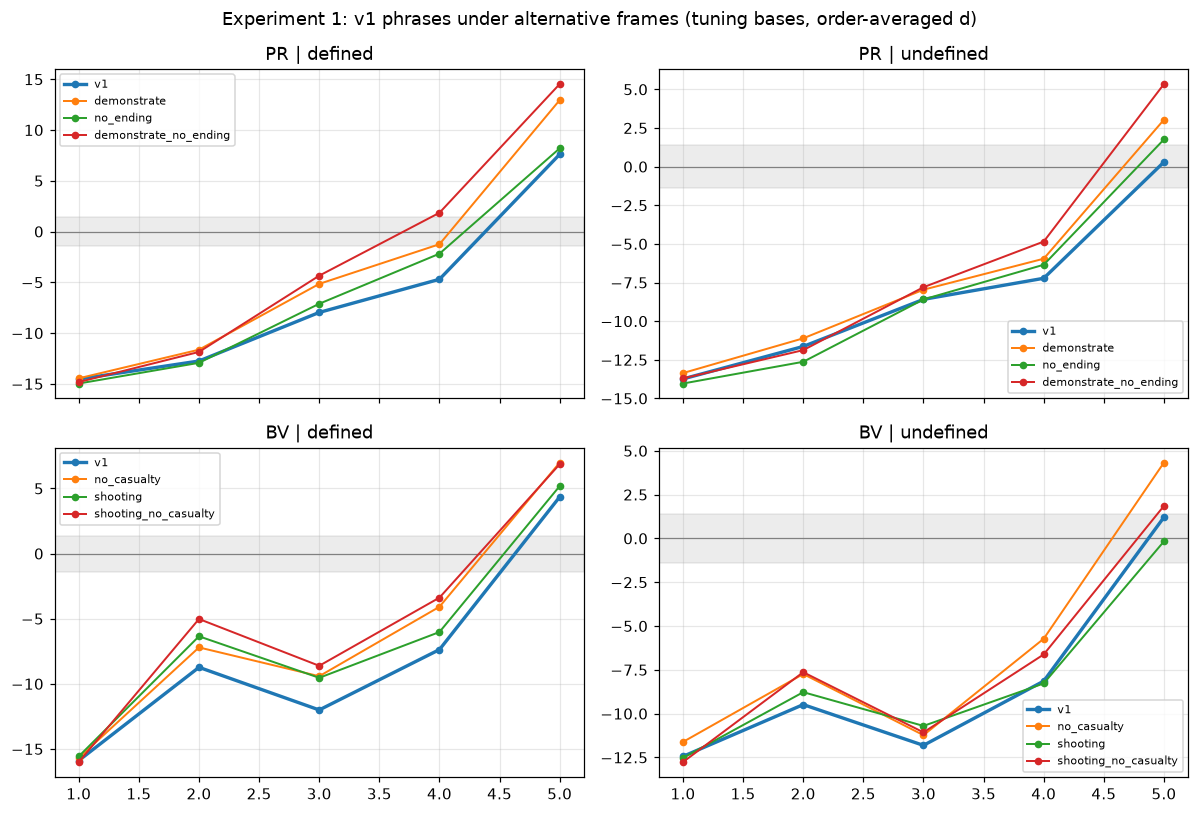

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for i, b in enumerate(BOUNDARIES):
    for j, v in enumerate(VERSIONS):
        ax = axes[i, j]
        ax.axhspan(-D_WINDOW, D_WINDOW, color="grey", alpha=0.15)
        ax.axhline(0, color="grey", lw=0.8)
        g = exp1[(exp1.boundary == b) & (exp1.version == v)]
        for fname, gg in g.groupby("frame", sort=False):
            m = gg.groupby("level").d.mean()
            ax.plot(m.index, m.values, "-o", ms=4, label=fname, lw=2.2 if fname == "v1" else 1.3)
        ax.set_title(f"{b} | {v}")
        ax.legend(fontsize=7)
fig.suptitle("Experiment 1: v1 phrases under alternative frames (tuning bases, order-averaged d)")
fig.tight_layout()

### Choose the Frame for the Rest of the Notebook
The cell picks the frame automatically: the one that maximizes the minimum anchor margin across both versions, among frames that keep both anchors correct in both versions, with the middle placed closest to the centre of the span as a tie-breaker. Override `FRAME_CHOICE` by hand if you prefer another, for example to change the frame as little as possible.

In [13]:
def pick_frame(tab, b):
    t = tab.loc[b]
    best = []
    for fname in FRAMES[b]:
        rows = t.xs(fname, level="frame")
        margin = min((-rows[1]).min(), rows[5].min())  # both anchors, worst version
        centre = (rows["mid_to_L1"] - 0.5).abs().max()
        best.append((margin > 0, margin - 2 * centre, fname))
    return max(best)[2]


FRAME_CHOICE = {b: pick_frame(exp1_tab, b) for b in BOUNDARIES}
FRAME_CHOICE

{'PR': 'demonstrate_no_ending', 'BV': 'no_casualty'}

## Experiment 2: A Factorial Pool of Evidence Sentences
v1 changed several things at once from level to level: the act (scuffle, then car damage, then stones), the source and the certainty. So the model's ordering could not be predicted. This pool separates the two factors, following PLAN.md's rule that each step should add evidence about *who acted or how certain the report is*:

- **cue**: the act that would make the event the higher class. PR: stones, car damage, shoving. BV: rifles, returning fire, armed-group membership.
- **certainty**: `c1` denied or disputed, `c2` unknown, `c3` one unconfirmed witness, `c4` several unconfirmed witnesses, `c5` confirmed for some participants or targets.

Every template has two wordings with the same facts, so the wording gap of each candidate is measured directly. The v1 anchors (L1, L5) and the v1 middle levels are included as references.

In [14]:
CERTAINTY = ["c1_disputed", "c2_unknown", "c3_one_witness", "c4_several_witnesses", "c5_confirmed_some"]
TEMPLATES = {
    "PR": {
        "c1_disputed": [
            "Organizers said the event was peaceful, though some accounts claimed participants {cue}.",
            "Some accounts claimed demonstrators {cue}, but organizers said the gathering stayed peaceful.",
        ],
        "c2_unknown": [
            "It is unclear whether participants {cue}.",
            "It is not known whether demonstrators {cue}.",
        ],
        "c3_one_witness": [
            "One witness said some participants {cue}, though this could not be confirmed.",
            "According to a single unconfirmed witness account, some demonstrators {cue}.",
        ],
        "c4_several_witnesses": [
            "Several witnesses said some participants {cue}, though this could not be confirmed.",
            "According to several unconfirmed witness accounts, some demonstrators {cue}.",
        ],
        "c5_confirmed_some": [
            "Some participants {cue}.",
            "A number of demonstrators {cue}.",
        ],
    },
    "BV": {
        "c1_disputed": [
            "Local officials said the people attacked were residents, though the attackers claimed they {cue}.",
            "The attackers claimed those targeted {cue}, but local officials said they were residents.",
        ],
        "c2_unknown": [
            "It is unclear whether the people attacked {cue}.",
            "It is not known whether those targeted {cue}.",
        ],
        "c3_one_witness": [
            "One witness said some of the people attacked {cue}, though this could not be confirmed.",
            "According to a single unconfirmed witness account, some of those targeted {cue}.",
        ],
        "c4_several_witnesses": [
            "Several witnesses said some of the people attacked {cue}, though this could not be confirmed.",
            "According to several unconfirmed witness accounts, some of those targeted {cue}.",
        ],
        "c5_confirmed_some": [
            "Some of the people attacked {cue}.",
            "A number of those targeted {cue}.",
        ],
    },
}
CUES = {
    "PR": {"stones": "threw stones", "car": "damaged a parked car", "shoving": "pushed and shoved bystanders"},
    "BV": {"rifles": "carried rifles", "fire": "returned fire", "group": "belonged to a rival armed group"},
}
EXCLUDED = LADDERS["excluded_terms"]


def pool_phrases(b):
    out = []
    for cue, cue_text in CUES[b].items():
        for c in CERTAINTY:
            ws = [t.format(cue=cue_text) for t in TEMPLATES[b][c]]
            out.append(dict(cue=cue, certainty=c, wordings=ws))
    for lvl, ws in V1_PHRASES[b].items():
        out.append(dict(cue="v1", certainty=f"v1_L{lvl}", wordings=ws))
    for p in out:
        for w in p["wordings"]:
            bad = [t for t in EXCLUDED if t in w.lower()]
            assert not bad, (w, bad)
    return out


exp2 = []
for b in BOUNDARIES:
    items = []
    for p in pool_phrases(b):
        for base in TUNE[b].to_dict("records"):
            for w, ev in enumerate(p["wordings"], start=1):
                items.append(dict(cue=p["cue"], certainty=p["certainty"], wording=w, base_id=base["base_id"], evidence=ev, text=render(FRAMES[b][FRAME_CHOICE[b]], base, ev)))
    exp2.append(probe(items, b))
exp2 = pd.concat(exp2, ignore_index=True)
print(exp2.groupby("boundary").size())

probe PR: 240 items x 4 prompts in 49.1s


probe BV: 240 items x 4 prompts in 49.4s
boundary
BV    480
PR    480
dtype: int64


### Pool Results: d by Cue × Certainty
Order-averaged d, averaged over tuning bases and wordings. Read across a row to see whether certainty raises d monotonically within a cue, and down a column to see how much the act itself matters. Cells inside the window (|d| ≤ 1.39) are good candidates for the middle level.

In [15]:
pool_tab = exp2.pivot_table(index=["boundary", "version", "cue"], columns="certainty", values="d", aggfunc="mean")
pool_tab = pool_tab[[c for c in CERTAINTY + [f"v1_L{i}" for i in range(1, 6)] if c in pool_tab.columns]]
pool_tab.style.background_gradient(cmap="RdBu_r", vmin=-10, vmax=10, axis=None).format("{:.1f}", na_rep="")

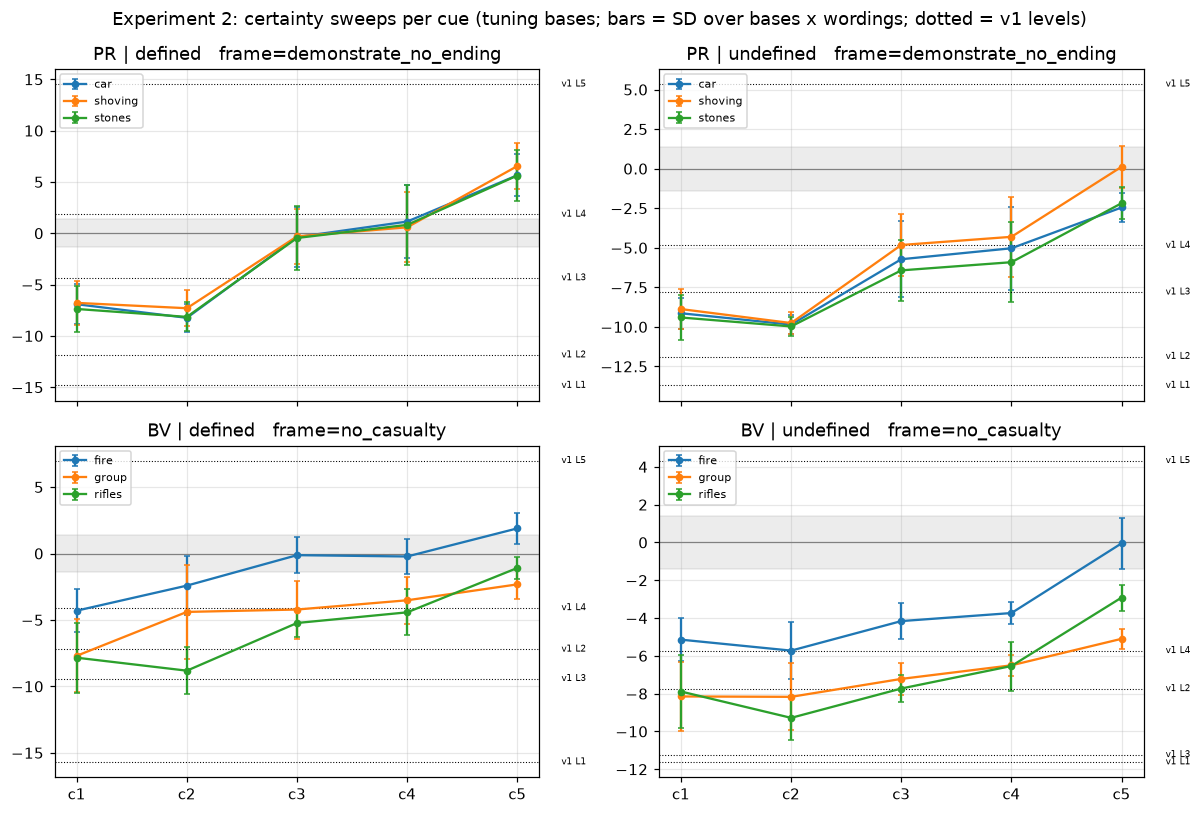

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for i, b in enumerate(BOUNDARIES):
    for j, v in enumerate(VERSIONS):
        ax = axes[i, j]
        ax.axhspan(-D_WINDOW, D_WINDOW, color="grey", alpha=0.15)
        ax.axhline(0, color="grey", lw=0.8)
        g = exp2[(exp2.boundary == b) & (exp2.version == v) & (exp2.cue != "v1")]
        for cue, gg in g.groupby("cue"):
            m = gg.groupby("certainty").d.agg(["mean", "std"]).reindex(CERTAINTY)
            ax.errorbar(range(len(CERTAINTY)), m["mean"], yerr=m["std"], fmt="-o", ms=4, capsize=2, label=cue)
        v1 = exp2[(exp2.boundary == b) & (exp2.version == v) & (exp2.cue == "v1")].groupby("certainty").d.mean()
        for name, val in v1.items():
            ax.axhline(val, color="k", ls=":", lw=0.7)
            ax.text(len(CERTAINTY) - 0.6, val, name.replace("v1_", "v1 "), fontsize=6, va="center")
        ax.set_xticks(range(len(CERTAINTY)), [c.split("_")[0] for c in CERTAINTY])
        ax.set_title(f"{b} | {v}   frame={FRAME_CHOICE[b]}")
        ax.legend(fontsize=7, loc="upper left")
fig.suptitle("Experiment 2: certainty sweeps per cue (tuning bases; bars = SD over bases x wordings; dotted = v1 levels)")
fig.tight_layout()

### Candidate Diagnostics
These are per-candidate statistics for both versions: mean d, the spread across bases, and the wording gap |W2 − W1|. They give a candidate's noise floor. A candidate whose wording gap is as large as a level step makes that step unreliable.

In [17]:
def candidate_table(pool):
    g = pool.groupby(["boundary", "cue", "certainty", "version"])
    t = g.agg(d=("d", "mean"), base_sd=("d", "std"), order_eff=("order_effect", "mean"))
    w = pool.pivot_table(index=["boundary", "cue", "certainty", "version", "base_id"], columns="wording", values="d")
    t["wording_gap"] = (w[2] - w[1]).abs().groupby(["boundary", "cue", "certainty", "version"]).mean()
    t = t.unstack("version")
    t.columns = [f"{a}_{v[:3]}" for a, v in t.columns]
    return t


cands = candidate_table(exp2)
cands

d_def  d_und  base_sd_def  base_sd_und  order_eff_def  order_eff_und  wording_gap_def  wording_gap_und
boundary cue     certainty                                                                                                                   
BV       fire    c1_disputed           -4.30  -5.14         1.61         1.13           0.94           7.27             2.56             1.93
                 c2_unknown            -2.42  -5.72         2.22         1.52          -0.27           9.26             3.65             2.47
                 c3_one_witness        -0.12  -4.16         1.36         0.97          -0.73           8.03             1.79             1.49
                 c4_several_witnesses  -0.22  -3.74         1.28         0.61          -1.26           8.13             0.74             0.44
                 c5_confirmed_some      1.89  -0.05         1.18         1.34          -2.28           7.24             1.43             1.49
         group   c1_disputed           -7.70  -8.15         2.74         1.81           2.40           8.05             5.10             3.44
                 c2_unknown            -4.40  -8.17         3.55         1.77           0.90           9.26             6.42             3.30
                 c3_one_witness        -4.22  -7.22         2.18         0.84           0.81           8.27             2.88             1.27
                 c4_several_witnesses  -3.52  -6.50         1.77         0.57          -0.06           8.04             1.42             0.39
                 c5_confirmed_some     -2.32  -5.10         1.10         0.52          -0.77           6.99             0.75             0.36
         rifles  c1_disputed           -7.84  -7.89         2.64         1.92           2.14           7.51             4.89             3.59
                 c2_unknown            -8.82  -9.28         1.78         1.16           0.91           8.19             2.89             1.91
                 c3_one_witness        -5.23  -7.73         1.06         0.72           0.27           7.77             0.63             0.44
                 c4_several_witnesses  -4.43  -6.54         1.73         1.30          -0.10           8.01             2.50             2.11
                 c5_confirmed_some     -1.09  -2.92         0.81         0.69          -0.99           8.23             0.80             0.50
         v1      v1_L1                -15.69 -11.61         1.07         2.09           3.46          10.79             2.00             3.97
                 v1_L2                 -7.20  -7.74         2.67         2.07           1.89           7.27             4.86             3.92
                 v1_L3                 -9.41 -11.23         3.43         1.59           0.62           8.27             6.41             2.97
                 v1_L4                 -4.08  -5.73         2.84         2.47          -0.21           7.49             4.92             4.55
                 v1_L5                  6.99   4.33         3.17         3.84          -1.60           1.61             5.63             7.07
PR       car     c1_disputed           -6.91  -9.14         1.96         0.98           1.68          -4.11             3.34             1.48
                 c2_unknown            -8.24  -9.85         1.38         0.60           0.48          -3.69             1.90             0.67
                 c3_one_witness        -0.37  -5.72         2.94         2.39           1.82          -3.68             5.18             4.39
                 c4_several_witnesses   1.14  -5.03         3.59         2.63           2.78          -3.40             6.47             4.83
                 c5_confirmed_some      5.65  -2.45         2.04         0.92           3.64          -0.01             1.47             0.51
         shoving c1_disputed           -6.78  -8.88         2.14         1.24           0.83          -3.56             3.77             2.13
                 c2_unknown            -7.30  -9.76         1.7

# Part 3: Build and Validate a Ladder

## Select Middle Levels by Target Probability
Each ladder keeps the v1 anchors at L1 and L5 and fills L2–L4 from the pool. By default a ladder uses **one cue**, and the three middle levels are three increasing certainty steps of it, so each step changes only certainty, as PLAN.md requires. The loss is the squared distance between each level's tuning-base d and its target, summed over **both task versions**, because one phrase list serves both. A penalty is added for the wording gap.

The targets are p(higher) = 0.2 / 0.5 / 0.8, which puts L2–L4 across the window rather than all at its centre. The last three cells of this part (selecting the ladder, validating it, and checking transfer) all read `TARGET_P` and `ALLOW_MIXED_CUES`, so change them and re-run those cells to try other placements or let levels use different cues.

In [18]:
TARGET_P = {2: 0.2, 3: 0.5, 4: 0.8}
TARGET_D = {k: math.log(p / (1 - p)) for k, p in TARGET_P.items()}
WORDING_PENALTY = 0.25
ALLOW_MIXED_CUES = False

phr = {b: {(p["cue"], p["certainty"]): p["wordings"] for p in pool_phrases(b)} for b in BOUNDARIES}
mean_d = exp2.groupby(["boundary", "cue", "certainty", "version"]).d.mean()
wgap = cands[["wording_gap_def", "wording_gap_und"]].mean(axis=1)


def ladder_loss(b, picks):
    loss = 0.0
    for lvl, key in zip((2, 3, 4), picks):
        for v in VERSIONS:
            loss += (mean_d[(b, *key, v)] - TARGET_D[lvl]) ** 2
        loss += WORDING_PENALTY * wgap[(b, *key)] ** 2
    return loss


def candidate_ladders(b):
    keys = [k for k in phr[b] if k[0] != "v1"]
    if ALLOW_MIXED_CUES:
        # any three distinct candidates, ordered by their mean d over versions
        order = lambda k: np.mean([mean_d[(b, *k, v)] for v in VERSIONS])
        for trio in combinations(keys, 3):
            yield tuple(sorted(trio, key=order))
    else:
        for cue in CUES[b]:
            for trio in combinations(CERTAINTY, 3):
                yield tuple((cue, c) for c in trio)


ranked = {}
for b in BOUNDARIES:
    scored = sorted((ladder_loss(b, picks), picks) for picks in candidate_ladders(b))
    ranked[b] = scored
    print(f"\n{b}: top 5 ladders (loss, [L2, L3, L4])")
    for loss, picks in scored[:5]:
        ds = {v: [round(mean_d[(b, *k, v)], 1) for k in picks] for v in VERSIONS}
        print(f"  {loss:7.2f}  {[k[0] + ':' + k[1].split('_')[0] for k in picks]}  def={ds['defined']}  und={ds['undefined']}")

CHOSEN = {b: ranked[b][0][1] for b in BOUNDARIES}
PROPOSED = {b: {1: V1_PHRASES[b][1], **{lvl: phr[b][k] for lvl, k in zip((2, 3, 4), CHOSEN[b])}, 5: V1_PHRASES[b][5]} for b in BOUNDARIES}
for b in BOUNDARIES:
    print(f"\n{b} proposed ladder (frame={FRAME_CHOICE[b]}):")
    for lvl, ws in PROPOSED[b].items():
        print(f"  L{lvl}: W1={ws[0]!r}\n       W2={ws[1]!r}")


PR: top 5 ladders (loss, [L2, L3, L4])
    71.27  ['shoving:c3', 'shoving:c4', 'shoving:c5']  def=[np.float64(-0.3), np.float64(0.6), np.float64(6.5)]  und=[np.float64(-4.8), np.float64(-4.3), np.float64(0.1)]
    93.34  ['car:c3', 'car:c4', 'car:c5']  def=[np.float64(-0.4), np.float64(1.1), np.float64(5.7)]  und=[np.float64(-5.7), np.float64(-5.0), np.float64(-2.5)]
   106.75  ['stones:c3', 'stones:c4', 'stones:c5']  def=[np.float64(-0.5), np.float64(0.8), np.float64(5.6)]  und=[np.float64(-6.4), np.float64(-5.9), np.float64(-2.2)]
   141.69  ['shoving:c1', 'shoving:c4', 'shoving:c5']  def=[np.float64(-6.8), np.float64(0.6), np.float64(6.5)]  und=[np.float64(-8.9), np.float64(-4.3), np.float64(0.1)]
   143.02  ['shoving:c1', 'shoving:c3', 'shoving:c5']  def=[np.float64(-6.8), np.float64(-0.3), np.float64(6.5)]  und=[np.float64(-8.9), np.float64(-4.8), np.float64(0.1)]

BV: top 5 ladders (loss, [L2, L3, L4])
    26.90  ['fire:c3', 'fire:c4', 'fire:c5']  def=[np.float64(-0.1), np.float

## Validate on Held-Out Bases with the Stage A Gate
This scores the proposed ladder, with all levels and both wordings, on the 18 held-out bases, then runs the **same `gate()`** as Part 1. Passing here gives good grounds to adopt the ladder as v2 and run a formal Stage A. Failing on held-out bases after passing on tuning bases means the selection overfitted, or the base-to-base variance is too large.

In [19]:
def validate(m, phrases=None, bases=HELD, label=""):
    phrases = phrases or PROPOSED
    vals = []
    for b in BOUNDARIES:
        vals.append(probe(ladder_items(b, FRAMES[b][FRAME_CHOICE[b]], phrases[b], bases[b]), b, m=m))
    val = pd.concat(vals, ignore_index=True)
    val_prompts = val.assign(mass=val.mass_min)  # gate() uses the median of the per-stimulus minimum mass
    g = gate(val, val_prompts)
    g.insert(0, "model", label or m["key"])
    return val, g


val, val_gate = validate(M)
display(val_gate)
display(scale_summary(val))

probe PR: 180 items x 4 prompts in 49.1s


probe BV: 180 items x 4 prompts in 49.5s


,model,boundary,version,anchor_L1,anchor_L5,rho_pos,ambig_bases,mass_median,PASS
0,llama3.2-3b,BV,defined,1.0,1.00,1.0,1.00,0.99,True
1,llama3.2-3b,BV,undefined,1.0,0.86,1.0,0.94,0.99,False
2,llama3.2-3b,PR,defined,1.0,1.00,1.0,0.44,1.00,False
3,llama3.2-3b,PR,undefined,1.0,0.97,1.0,1.00,1.00,True


,boundary,version,d_L1,d_L5,span,mid_mean,mid_to_L1,|wording|,|order|,inversions
0,BV,defined,-15.71,6.68,22.39,0.22,0.71,1.87,2.00,0.15
1,BV,undefined,-11.74,4.00,15.74,-2.92,0.56,1.97,8.00,0.16
2,PR,defined,-14.86,14.16,29.02,1.86,0.58,1.31,1.84,0.04
3,PR,undefined,-13.72,4.06,17.78,-3.47,0.58,3.00,2.56,0.10


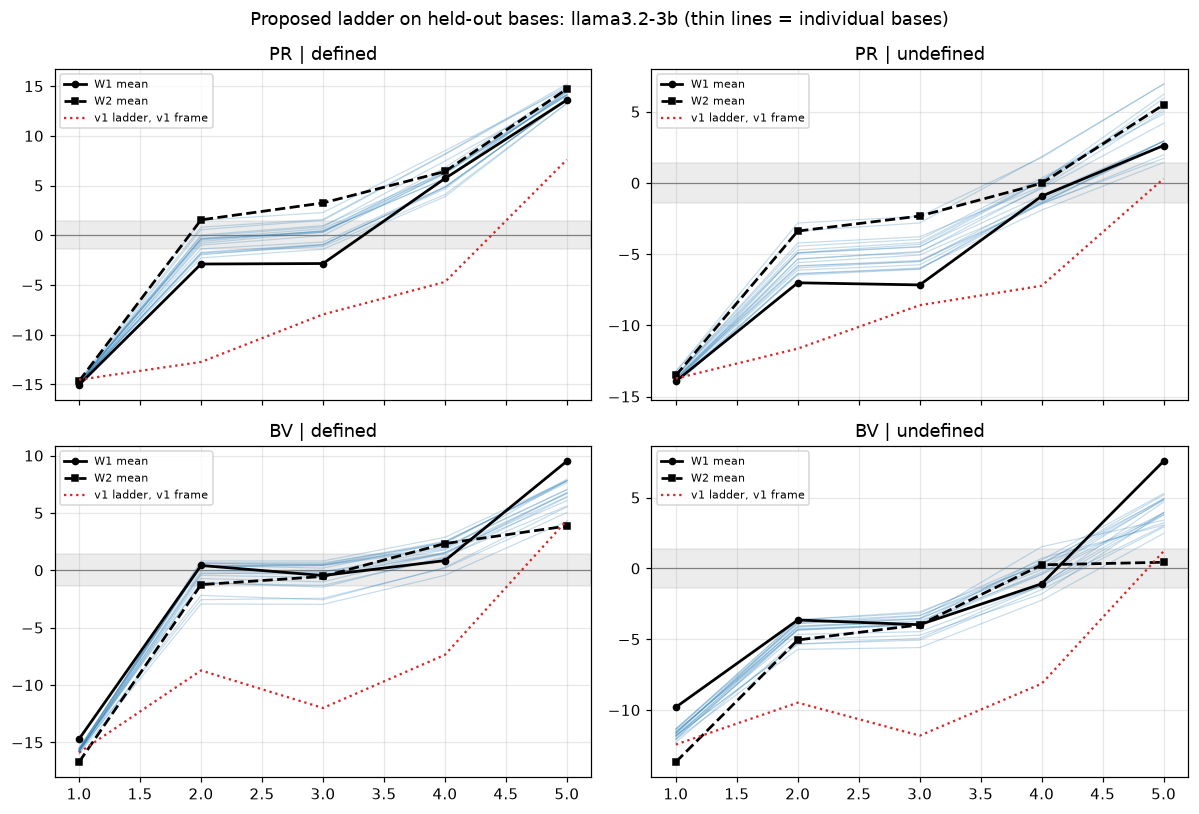

In [20]:
def plot_val(val, title):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
    for i, b in enumerate(BOUNDARIES):
        for j, v in enumerate(VERSIONS):
            ax = axes[i, j]
            ax.axhspan(-D_WINDOW, D_WINDOW, color="grey", alpha=0.15)
            ax.axhline(0, color="grey", lw=0.8)
            g = val[(val.boundary == b) & (val.version == v)]
            for base, gg in g.groupby("base_id"):
                m = gg.groupby("level").d.mean()
                ax.plot(m.index, m.values, color="tab:blue", alpha=0.25, lw=0.8)
            for w, gg in g.groupby("wording"):
                m = gg.groupby("level").d.mean()
                ax.plot(m.index, m.values, "o-" if w == 1 else "s--", color="k", lw=1.8, ms=4, label=f"W{w} mean")
            if b in exp1.boundary.values:  # v1 reference on tuning bases, same frame
                ref = exp1[(exp1.boundary == b) & (exp1.version == v) & (exp1.frame == "v1")].groupby("level").d.mean()
                ax.plot(ref.index, ref.values, ":", color="tab:red", label="v1 ladder, v1 frame")
            ax.set_title(f"{b} | {v}")
            ax.legend(fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()


plot_val(val, f"Proposed ladder on held-out bases: {M['key']} (thin lines = individual bases)")

## Transfer Check on Qwen3-4B (Exploratory bf16)
The phrase list is shared across models, but each model × boundary × version is gated on its own. A ladder fitted to Llama could therefore fail for Qwen. This cell scores the proposed ladder on Qwen3-4B in **bf16**, which fits on the A4000. Its d can be off by up to about 0.75 nats (HANDOFF.md), which is fine for judging placement but not for formal scores. If Qwen sits far from Llama, choose the ladder on the combined loss over both models instead: re-run Experiment 2 with `m=Q` and sum the losses.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:  38%|███▊      | 150/398 [00:00<00:00, 502.98it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 1297.33it/s]

probe PR: 180 items x 4 prompts in 72.6s


probe BV: 180 items x 4 prompts in 75.7s


,model,boundary,version,anchor_L1,anchor_L5,rho_pos,ambig_bases,mass_median,PASS
0,llama3.2-3b,BV,defined,1.0,1.00,1.0,1.00,0.99,True
1,llama3.2-3b,BV,undefined,1.0,0.86,1.0,0.94,0.99,False
2,llama3.2-3b,PR,defined,1.0,1.00,1.0,0.44,1.00,False
3,llama3.2-3b,PR,undefined,1.0,0.97,1.0,1.00,1.00,True
4,qwen3-4b (bf16),BV,defined,1.0,1.00,1.0,0.61,1.00,True
5,qwen3-4b (bf16),BV,undefined,1.0,0.58,1.0,0.00,0.99,False
6,qwen3-4b (bf16),PR,defined,1.0,1.00,1.0,0.11,1.00,False
7,qwen3-4b (bf16),PR,undefined,1.0,1.00,1.0,0.17,1.00,False


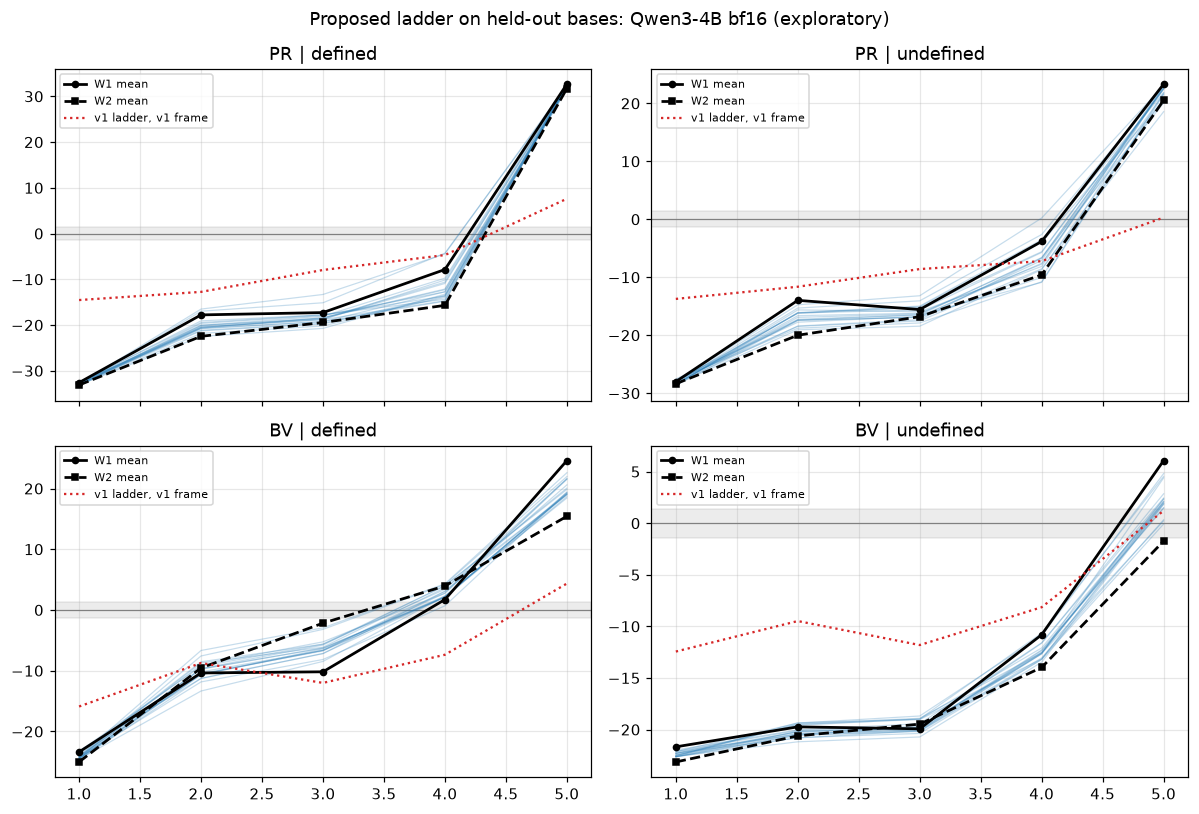

In [21]:
Q = load_probe_model("qwen3-4b", dtype_override="bfloat16")
val_q, val_q_gate = validate(Q, label="qwen3-4b (bf16)")
display(pd.concat([val_gate, val_q_gate], ignore_index=True))
plot_val(val_q, "Proposed ladder on held-out bases: Qwen3-4B bf16 (exploratory)")

## Proposed v2 Phrase List (for Review, Not Written)
The cell prints the selected frame and phrases in the `ladders.json` schema. To adopt them, follow HANDOFF.md:
1. Record them as a new ladder version with a revision note.
2. Rebuild the snapshot into a new directory.
3. Rerun Stage A formally for both models (Qwen in fp32).

In [22]:
proposal = {}
for b in BOUNDARIES:
    levels = []
    for lvl, ws in PROPOSED[b].items():
        src = "v1 anchor" if lvl in (1, 5) else f"{CHOSEN[b][lvl - 2][0]} / {CHOSEN[b][lvl - 2][1]}"
        levels.append(dict(level=lvl, source=src, wordings=ws))
    proposal[b] = dict(frame=FRAMES[b][FRAME_CHOICE[b]], frame_variant=FRAME_CHOICE[b], levels=levels)
print(json.dumps(proposal, indent=2))
(SCRATCH / "proposed_v2_ladders.json").write_text(json.dumps(proposal, indent=2))
print("\nsaved to", SCRATCH / "proposed_v2_ladders.json")

{
  "PR": {
    "frame": "On 12 June 2025, {actors} gathered {place}{country} to demonstrate against {grievance}. {evidence}",
    "frame_variant": "demonstrate_no_ending",
    "levels": [
      {
        "level": 1,
        "source": "v1 anchor",
        "wordings": [
          "Participants remained peaceful throughout.",
          "The demonstrators stayed nonviolent for the entire event."
        ]
      },
      {
        "level": 2,
        "source": "shoving / c3_one_witness",
        "wordings": [
          "One witness said some participants pushed and shoved bystanders, though this could not be confirmed.",
          "According to a single unconfirmed witness account, some demonstrators pushed and shoved bystanders."
        ]
      },
      {
        "level": 3,
        "source": "shoving / c4_several_witnesses",
        "wordings": [
          "Several witnesses said some participants pushed and shoved bystanders, though this could not be confirmed.",
          "According t


## Read-Out from Parts 2–3 (Run 2026-11-05, Llama bf16 + Qwen bf16 Exploratory)
Written from the outputs above. Re-check it if the pool, frames or targets change.

1. **The frame matters most for the anchors.** In PR, *demonstrate against* plus dropping the closing sentence raises the undefined L5 anchor from p ≈ 0.57 to 1.0. In BV, dropping *Two people were killed* raises the undefined L5 anchor from 0.77 to 0.99. On its own the frame change shifts the middle by only 1–3 nats.
2. **In PR, certainty is the lever and the act barely matters.** "Disputed" and "unknown" (c1, c2) stay near the floor (d ≈ −7 to −10) for every act. A witness attribution (c3) adds about 7 nats, c3 → c4 adds only about 1, and c5 ("some participants did X") adds about 5 more. Stones, car damage and shoving fall within about 1 nat of each other. v1 failed because its L2 and L3 were c1/c2-type statements.
3. **In BV, only *fighting back* moves the model.** "Returned fire" reaches the window. "Carried rifles" and "belonged to a rival armed group" stay at −1 to −9 even when confirmed. This matches the Battle definition, *capable of harming each other*.
4. **Structural problem: the two task versions sit about 4–6 nats apart in the middle.** For example, PR stones c4 scores +0.8 defined and −5.9 undefined, and BV fire c4 scores −0.2 defined and −3.7 undefined. One shared 5-level phrase list cannot put the middle in the window for both versions. On held-out bases: BV-defined and PR-undefined pass, BV-undefined fails (L5 anchor 0.86) and PR-defined fails (ambiguous bases 0.44, middle drifts about 2 nats upward on held-out bases).
5. **Qwen does not transfer.** Its middle levels sit lower (ambiguous bases 0.00–0.61). A ladder fitted to one model will not pass the other's gate.
6. **Order bias in BV-undefined is about 8 nats, for every phrase.** Averaging the orders removes it from the mean, but it is larger than most level steps.

**Options (the decision is a design one):**
- (a) **A longer ladder with one shared phrase list.** Add finer certainty steps in the c3–c5 range so each version and model has *some* level in the window. The gate only needs one middle level per base, so this works within the gate, but it changes PLAN's 5-level design.
- (b) Separate phrase lists for each version or model. These pass more easily but break the matched-evidence comparison between versions and models.
- (c) Keep 5 levels and choose them on the combined loss over both models and versions. This is likely to leave every middle level in the window for *no* combination.
